In [8]:
!pip install langchain langchain-text-splitters langchain_openai langchain-chroma langchain-community langchain-core -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 38.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.


In [9]:
from typing_extensions import TypedDict


class GraphState(TypedDict):
    question: str
    vectordb_status_flag: str
    context: list
    response: str

In [10]:
import os
from google.colab import userdata
from langchain_openai import ChatOpenAI, OpenAIEmbeddings

os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
llm = ChatOpenAI(model="gpt-4.1-mini")
embed_model = OpenAIEmbeddings(model="text-embedding-ada-002")

llm.invoke("hi").content, len(embed_model.embed_query("hi"))

('Hello! How can I assist you today?', 1536)

In [26]:
import os

# from langchain.chains.question_answering import load_qa_chain
from langchain_text_splitters import CharacterTextSplitter
from langchain_chroma import Chroma
from langchain_community.document_loaders import TextLoader


def validate_database(state):
    """
    Validates the database state to ensure it is ready.

    Args:
        state (GraphState): The state of the graph database.

    Returns:
        update vectordb_status_flag
    """

    print("Validating database state...")
    persist_directory = os.path.join(os.getcwd(), "database", "chromadb")

    vector_store = Chroma(
        collection_name="example_collection",
        embedding_function=embed_model,
        persist_directory=persist_directory,  # Where to save data locally, remove if not necessary
    )

    all_ids = vector_store.get()["ids"]

    if len(all_ids) > 0:
        print("Database already prepared, skipping preparation.")
        return {"vectordb_status_flag": "true"}

    return {"vectordb_status_flag": "false"}


def prepare_database(state):
    """
    Prepares the database for use by validating its state.

    Args:
        state (GraphState): The state of the graph database.

    Returns:
        GraphState: The updated state of the graph database.
    """

    print("Preparing database...")
    try:
        persist_directory = os.path.join(os.getcwd(), "database", "chromadb")

        vector_store = Chroma(
            collection_name="example_collection",
            embedding_function=embed_model,
            persist_directory=persist_directory,  # Where to save data locally, remove if not necessary
        )

        # Load and chunk documents
        loader = TextLoader("/content/database/sample_doc.txt")
        documents = loader.load()
        text_splitter = CharacterTextSplitter(chunk_size=500, chunk_overlap=20)
        texts = text_splitter.split_documents(documents)

        vector_store.add_documents(texts)

        print("Database prepared successfully.")
        status = "true"
    except Exception as e:
        print(f"Error preparing database: {e}")
        status = "false"

    return {"vectordb_status_flag": status}


def retrieve_context(state):
    """
    Retrieves context from the graph database based on the current state.

    Args:
        state (GraphState): The state of the graph database.

    Returns:
        str: The context retrieved from the graph database.
    """

    print("Retrieving context...")
    question = state["question"]

    persist_directory = os.path.join(os.getcwd(), "database", "chromadb")
    vector_store = Chroma(
        collection_name="example_collection",
        embedding_function=embed_model,
        persist_directory=persist_directory,  # Where to save data locally, remove if not necessary
    )

    # retrieved_documents = vector_store.similarity_search_with_relevance_scores(query=question, k=5)
    retriver = vector_store.as_retriever(
        search_type="similarity_score_threshold",
        search_kwargs={"k": 5, "score_threshold": 0.5},
    )

    relevant_doc = retriver.invoke(question)

    return {"context": relevant_doc}





from langchain_core.prompts import PromptTemplate
from langchain_core.prompts.chat import (
    ChatPromptTemplate,
    HumanMessagePromptTemplate,
    SystemMessagePromptTemplate,
)

prompt_template = """Use the following pieces of context to answer the question at the end. If you don't know the answer, just say that you don't know, don't try to make up an answer.

{context}

Question: {question}
Helpful Answer:"""

PROMPT = PromptTemplate(
    template=prompt_template, input_variables=["context", "question"]
)


# ----------------------------------------------------------------- #

system_template = """Use the following pieces of context to answer the user's question.
If you don't know the answer, just say that you don't know, don't try to make up an answer.
----------------
{context}"""
messages = [
    SystemMessagePromptTemplate.from_template(system_template),
    HumanMessagePromptTemplate.from_template("{question}"),
]
CHAT_PROMPT = ChatPromptTemplate.from_messages(messages)





def generate_response(state):
    """
    Generates a response based on the current state of the graph database.

    Args:
        state (GraphState): The state of the graph database.

    Returns:
        str: The generated response.
    """

    print("Generating response...")

    question = state.get("question", "")
    context = state.get("context", "")

    chain = CHAT_PROMPT | llm

    # Pass the context key mapped properly matching CHAT_PROMPT template expectations
    response = chain.invoke({"context": context, "question": question})

    return {"response": response.content}


# prompt | llm | parser

In [27]:
def route_question(state):
    """
    Routes the question to the appropriate function based on the current state.

    Args:
        state (GraphState): The state of the graph database.

    Returns:
        str: The response generated based on the routed question.
    """

    print("Routing question...")

    vectordb_status_flag = state.get("vectordb_status_flag", "false")

    if vectordb_status_flag == "false":
        return 'prepare'

    else:
        return "retrieve"

In [28]:
from langgraph.graph import END, StateGraph


workflow = StateGraph(GraphState)


workflow.add_node("validate_database", validate_database)
workflow.add_node("prepare_database", prepare_database)
workflow.add_node("retrieve_context", retrieve_context)
workflow.add_node("generate_response", generate_response)

workflow.set_entry_point("validate_database")


workflow.add_conditional_edges(
    "validate_database",
    route_question,
    {
        "prepare": "prepare_database",
        "retrieve": "retrieve_context"
    },
)

workflow.add_edge("prepare_database", "retrieve_context")
workflow.add_edge("retrieve_context", "generate_response")
workflow.add_edge("generate_response", END)


graph = workflow.compile()

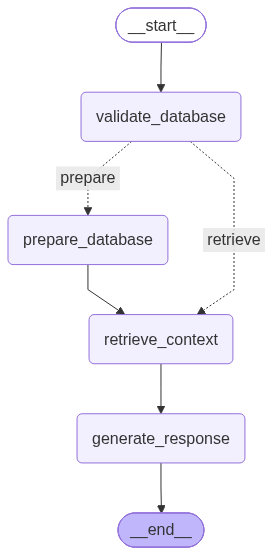

In [29]:
graph

In [30]:
output = graph.invoke(
    {
        "question": "who is a generalist?",
    }
)

Validating database state...
Database already prepared, skipping preparation.
Routing question...
Retrieving context...
Generating response...


In [31]:
output["response"]  # Access the response from the output dictionary

'A generalist is someone who has knowledge of several subjects or skills. They can adapt to different tasks, connect ideas, and understand how different parts of a problem fit together. Generalists are often useful in roles that require flexibility, collaboration, and problem-solving across teams.'

In [32]:
output

{'question': 'who is a generalist?',
 'vectordb_status_flag': 'true',
 'context': [Document(id='90ebf3f4-e5cb-4c38-8eab-327ed025b25c', metadata={'source': '/content/database/sample_doc.txt'}, page_content='Generalist vs. Specialist\nPeople build expertise in different ways. Some learn across many fields, while others focus deeply\non one area. Both approaches have value, and the right choice depends on the work and goals.\nWhat Is a Generalist?\nA generalist has knowledge of several subjects or skills. They can adapt to different tasks, connect\nideas, and understand how different parts of a problem fit together. Generalists are often useful in\nroles that require flexibility, collaboration, and problem-solving across teams.\nWhat Is a Specialist?\nA specialist focuses on one subject or skill and develops deep expertise in it. They can handle\ncomplex problems in their area and bring detailed knowledge and experience. Specialists are\nvaluable when a task requires precision or advanced